# ТК 7-8 (ПР4): бинарная логистическая регрессия
Бинарная логистическая регрессия - это модель для оценки вероятности принадлежности объекта к одному из двух классов на основе линейной комбинации признаков.

Пример из методички (расходы на рекламу) + договоры insclass: сравнение двух способов обучения бинарной логистической регрессии.

## Импорты

In [1]:
import os
import sys
import time
sys.path.insert(0, os.getcwd())
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from logistic_regression import LogisticRegressionGD
from data_pipeline import encode_string_features, load_clean_split, scaled_matrix

## Данные примера

Методом наименьших квадратов (МНК) называют способ оценки параметров линейной модели, минимизирующий сумму квадратов отклонений предсказаний от наблюдаемых значений.

Выбросы - это наблюдения, существенно отличающиеся от основной массы данных и способные искажать оценки параметров модели.

Сигмоидой называют гладкую S-образную функцию, переводящую любое вещественное число в интервал (0, 1); в логистической регрессии через неё выражается вероятность класса.

На scatter-диаграмме ниже по оси X отложены расходы на рекламу, а по оси Y — бинарный эффект. Каждая точка соответствует одному наблюдению, а выбросы с большими значениями x легко заметить в правой части графика.

В данных есть выбросы x=100 и x=200. Они сильно влияют на МНК; логистическая кривая устойчивее.

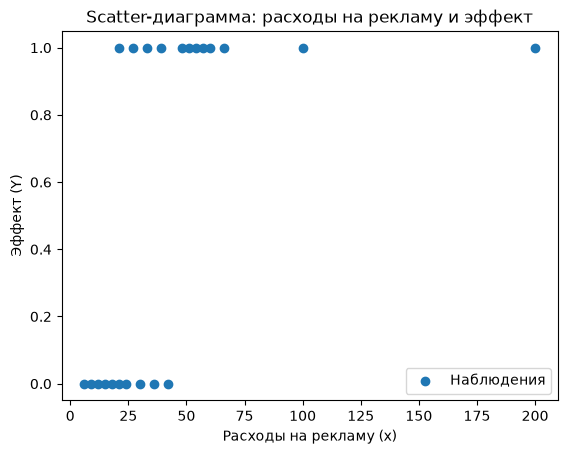

In [2]:
# x — расходы на рекламу, Y — эффект (0/1)
x = pd.DataFrame(np.array([39, 36, 60, 21, 27, 12, 51, 57, 54, 42, 18, 9, 48, 66, 6, 30, 24, 33, 15, 21, 100, 200]))
Y = pd.DataFrame(np.array([1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1]))
plt.scatter(x, Y, label="Наблюдения")
plt.title("Scatter-диаграмма: расходы на рекламу и эффект")
plt.xlabel("Расходы на рекламу (x)")
plt.ylabel("Эффект (Y)")
plt.legend()

## МНК и логистическая регрессия

МНК даёт значения вне [0,1] и чувствителен к выбросам. Для бинарного отклика используем логистическую регрессию.

На следующем графике красная прямая показывает аппроксимацию данных методом наименьших квадратов. Обратите внимание, что предсказанные значения могут выходить за допустимый для вероятностей диапазон [0, 1], что демонстрирует ограничение МНК для бинарного отклика.

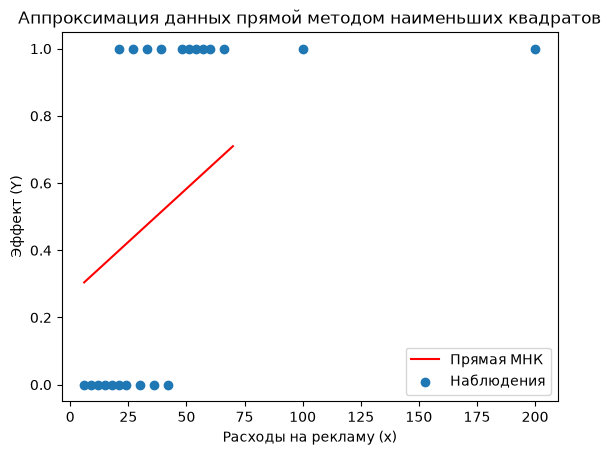

In [3]:
# МНК; чувствителен к выбросам x=100, 200
a1 = ((x - x.mean()) * (Y - Y.mean())).mean() / ((x - x.mean()) ** 2).mean()
a0 = Y.mean() - a1 * x.mean()
x_space = np.linspace(6, 70, 20)
Y_pred = a0.item() + a1.item() * x_space
plt.plot(x_space, Y_pred, 'r', label="Прямая МНК")
plt.scatter(x, Y, label="Наблюдения")
plt.title("Аппроксимация данных прямой методом наименьших квадратов")
plt.xlabel("Расходы на рекламу (x)")
plt.ylabel("Эффект (Y)")
plt.legend()

## Обучение моделей

Intercept (свободный член) - это слагаемое линейной комбинации признаков, не зависящее от входных переменных; в матричной записи его задают константным столбцом из единиц.

Функцией правдоподобия (LL) называют функцию, показывающую, насколько вероятны наблюдаемые данные при данных параметрах модели; обучение стремится максимизировать её.

Кросс-энтропия (CE) - это функция потерь, равная отрицанию логарифма правдоподобия; её минимизация эквивалентна максимизации правдоподобия.

Градиентным спуском и противоположным ему подъёмом называют итерационные методы оптимизации, на каждом шаге сдвигающие параметры модели против градиента функции потерь (спуск) или по градиенту целевой функции (подъём).

Далее к матрице признаков добавляется константный столбец intercept, после чего модели обучаются двумя способами: подъёмом правдоподобия (LL) и спуском по кросс-энтропии (CE).

In [4]:
# Intercept-столбец: свободный сдвиг сигмоиды
x_ = x.copy()
intercept = np.ones((x.shape[0], 1))
x_ = pd.DataFrame(np.concatenate((intercept, x), axis=1))

start_time_CE = time.time()
regr_CE = LogisticRegressionGD()
steps_CE, errors_CE = regr_CE.fit(x_, Y, alpha=0.01, epsylon=0.01, max_steps=10000, Rtype="CE")
print(f"Время обучения CE: {time.time() - start_time_CE} сек.")

start_time_LL = time.time()
regr_LL = LogisticRegressionGD()
steps_LL, errors_LL = regr_LL.fit(x_, Y, alpha=0.01, epsylon=0.01, max_steps=10000, Rtype="LL")
print(f"Время обучения LL: {time.time() - start_time_LL} сек.")

Время обучения CE: 0.12454819679260254 сек.
Время обучения LL: 0.11770105361938477 сек.


## Предсказания моделей

На двух соседних scatter-графиках сравниваются истинные метки эффекта и предсказанные моделями CE и LL вероятности положительного класса. По оси X отложены расходы на рекламу, по оси Y — вероятность эффекта; чем ближе цветная точка к значению истинной метки, тем точнее предсказание.

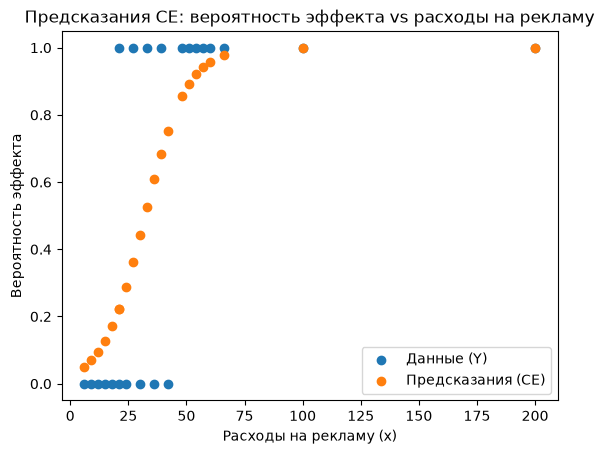

array([[-3.59901953],
       [ 0.11215758]])

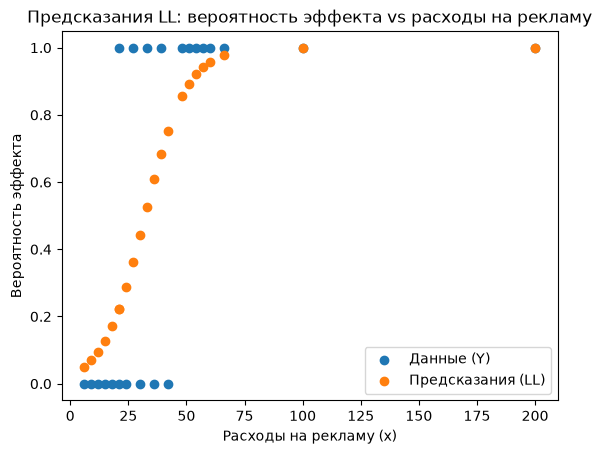

array([[-3.59901953],
       [ 0.11215758]])

In [5]:
# Предсказания и коэффициенты CE и LL
plt.scatter(x, Y, label="Данные (Y)")
plt.scatter(x, regr_CE.predict(x_), label="Предсказания (CE)")
plt.title("Предсказания CE: вероятность эффекта vs расходы на рекламу")
plt.xlabel("Расходы на рекламу (x)")
plt.ylabel("Вероятность эффекта")
plt.legend()
plt.show()
display(regr_CE.coefs())
plt.scatter(x, Y, label="Данные (Y)")
plt.scatter(x, regr_LL.predict(x_), label="Предсказания (LL)")
plt.title("Предсказания LL: вероятность эффекта vs расходы на рекламу")
plt.xlabel("Расходы на рекламу (x)")
plt.ylabel("Вероятность эффекта")
plt.legend()
plt.show()
display(regr_LL.coefs())

## Сравнение кривых обучения и метрик

Кривая обучения - это график изменения функции потерь (или ошибки) по мере итераций обучения, показывающий сходимость оптимизации.

Accuracy (доля правильных ответов) - это доля объектов, для которых модель предсказала класс, совпавший с истинной меткой.

Precision (точность) - это доля объектов, отнесённых моделью к положительному классу, которые действительно ему принадлежат.

Recall (полнота) - это доля объектов положительного класса, которые модель правильно распознала.

F1-мера - это среднее гармоническое точности и полноты, объединяющее обе метрики в одно число.

На графике ниже по горизонтали отложены номера итераций градиентного спуска/подъёма, а по вертикали — значения ошибки CE и логарифма правдоподобия LL. Кривая CE убывает, а кривая LL растёт к нулю — обе сходятся, и их зеркальность отражает то, что LL и CE отличаются лишь знаком.

В текстовом выводе приведены accuracy, precision, recall и F1-мера на обучающей выборке для CE и LL.

CE accuracy: 0    0.818182
dtype: float64 precision: 0.8333333333333334 recall: 0.8333333333333334 f1: 0.8333333333333334
LL accuracy: 0    0.818182
dtype: float64 precision: 0.8333333333333334 recall: 0.8333333333333334 f1: 0.8333333333333334


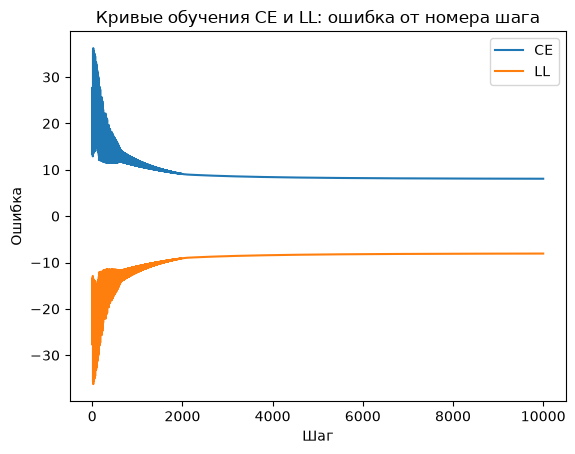

In [6]:
# Сравниваем CE и LL по кривым обучения и метрикам
plt.plot(steps_CE, errors_CE, label="CE")
plt.plot(steps_LL, errors_LL, label="LL")
plt.title("Кривые обучения CE и LL: ошибка от номера шага")
plt.xlabel("Шаг")
plt.ylabel("Ошибка")
plt.legend()
for tag, m in [("CE", regr_CE), ("LL", regr_LL)]:
    print(tag, "accuracy:", m.accuracy(x_, Y), "precision:", m.precision(x_, Y), "recall:", m.recall(x_, Y), "f1:", m.f1(x_, Y))

## Данные insclass

Отложенной выборкой называют часть данных, исключаемую из обучения: валидационную — для настройки и промежуточной проверки модели, тестовую — для окончательной оценки качества.

Пропуски - это ячейки датасета, в которых значение признака не задано (отсутствующие значения, NA).

Страховые договоры: 151406 строк, 29 полей разных типов, с пропусками. Тестового файла нет — отложенная выборка 70/15/15.

## Очистка данных

Очисткой данных называют удаление или исправление некорректных и неполных записей перед обучением модели.

Датасет содержит 29 полей разных типов: 6 строковых (variable_1, variable_5, variable_20, variable_21, variable_22, variable_28) и ряд числовых, почти полностью состоящих из пропусков (например, variable_15 — 99.99% пустых значений). Для модели оставили 10 числовых признаков по списку методички плюс целевую переменную target; почти пустые числовые поля в модель не берутся. Шесть строковых полей (бонус-малус, страна-производитель, канал продаж, марка, модель и тип транспортного средства) не масштабируются, а кодируются отдельно — см. раздел «Кодирование строковых признаков».

После выбора признаков строки с пропусками в оставшихся полях удалены целиком: их немного — 4877 из 151406, то есть менее 4%, поэтому удаление безопаснее, чем восстановление значений страховых признаков. Далее данные масштабируются (см. следующий раздел).

In [7]:
TRAIN_CSV = os.path.join("docs", "insclass_train.csv")
raw = pd.read_csv(TRAIN_CSV)
print("raw shape:", raw.shape)
used_features = ["variable_4", "variable_6", "variable_12", "variable_13", "variable_14",
                 "variable_16", "variable_17", "variable_18", "variable_19", "variable_27"]
print("NA counts in used features:")
print(raw[used_features].isna().sum())
train, validate, test, scaler = load_clean_split(TRAIN_CSV)
removed = len(raw) - len(train) - len(validate) - len(test)
print("removed rows:", removed)
print("sizes:", len(train), len(validate), len(test))
train.describe()

raw shape: (151406, 29)
NA counts in used features:
variable_4        0
variable_6      111
variable_12    1528
variable_13    1657
variable_14    2927
variable_16      12
variable_17      12
variable_18      12
variable_19       0
variable_27    2067
dtype: int64
removed rows: 4877
sizes: 102570 21979 21980


,variable_4,variable_6,variable_12,variable_13,variable_14,variable_16,variable_17,variable_18,variable_19,variable_27,target
count,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000,102570.000000
mean,11.386858,117.694764,133.191032,49.977325,87.449536,132.203073,81.784429,109.263724,139.957882,15.546701,0.082539
std,6.910702,50.007569,87.880125,15.481846,32.178495,42.412603,12.375472,67.490633,18.592180,11.992183,0.275185
min,2.000000,1.000000,0.000000,20.731525,80.985224,28.130592,80.985224,19.287400,102.172584,0.000000,0.000000
25%,6.000000,86.000000,66.827923,38.519899,80.985224,98.648082,80.985224,80.985224,127.113159,6.447149,0.000000
50%,10.000000,107.000000,121.261910,46.438089,80.985224,118.116608,80.985224,80.985224,148.905712,12.200897,0.000000
75%,14.000000,137.000000,175.818287,59.293870,80.985224,162.514016,80.985224,139.401847,148.905712,20.731525,0.000000
max,80.000000,1975.000000,842.774591,114.436034,273.413449,214.256572,273.413449,376.183487,284.372991,95.869364,1.000000


## Масштабирование признаков

StandardScaler - это преобразование признаков, вычитающее среднее и делящее значения на стандартное отклонение, чтобы привести признаки к единому масштабу.

Утечкой данных (data leakage) называют ситуацию, когда при обучении модели используется информация из валидационной или тестовой выборки, из-за чего оценка качества оказывается завышенной.

Признаки insclass масштабируются только по обучающей выборке, чтобы исключить утечку информации о валидационной и тестовой частях.

## Кодирование строковых признаков

Целевым кодированием (mean encoding) называют замену категориального признака средним значением целевой переменной по каждой категории, рассчитанным на обучающей выборке.

Строковые поля нельзя подставить в матричные вычиснения напрямую. Вместо one-hot кодирования, которое добавило бы сотни разреженных столбцов (у variable_22 — 1475 уникальных значений), применяется целевое кодирование: категория заменяется долей рисковых договоров в ней на обучающей выборке. Редкие категории (менее 100 договоров) и категории, отсутствующие в обучении, кодируются общей средней по обучающей выборке; отображение подбирается только по обучению, чтобы исключить утечку. Каждый строковый признак даёт ровно один числовой столбец, поэтому матрица признаков растёт с 11 до 17 столбцов.

In [8]:
# StandardScaler fit только на train, чтобы не допустить утечки.
# 10000 шагов, как в методичке.
# Строковые признаки -> 6 числовых столбцов целевым кодированием (маппинг по train).
train_s, validate_s, _, _ = load_clean_split(TRAIN_CSV, with_string_cols=True)
Xtr, ytr = scaled_matrix(train_s, scaler)
Xva, yva = scaled_matrix(validate_s, scaler)
Xtr = np.hstack([Xtr, encode_string_features(train_s, train_s)])
Xva = np.hstack([Xva, encode_string_features(train_s, validate_s)])
print("матрица признаков (train):", Xtr.shape)
m_ll, m_ce = LogisticRegressionGD(), LogisticRegressionGD()
t0 = time.time(); m_ll.fit(Xtr, ytr, max_steps=10000, Rtype="LL"); t_ll = time.time() - t0
t0 = time.time(); m_ce.fit(Xtr, ytr, max_steps=10000, Rtype="CE"); t_ce = time.time() - t0
for tag, m, t in [("LL", m_ll, t_ll), ("CE", m_ce, t_ce)]:
    print(tag, f"{t:.1f} сек.", "train f1:", m.f1(Xtr, ytr),
          "validate accuracy:", float(np.asarray(m.accuracy(Xva, yva)).mean()),
          "validate precision:", m.precision(Xva, yva),
          "validate recall:", m.recall(Xva, yva),
          "validate f1:", m.f1(Xva, yva))

матрица признаков (train): (102569, 17)


LL 26.7 сек. train f1: 0.0 validate accuracy: 0.9167842031029619 validate precision: 0.0 validate recall: 0.0 validate f1: 0.0


CE 30.2 сек. train f1: 0.0 validate accuracy: 0.9167842031029619 validate precision: 0.0 validate recall: 0.0 validate f1: 0.0


## Выводы
Дисбаланс классов - это сильное неравенство числа объектов разных классов в выборке, затрудняющее обучение и интерпретацию метрик.

- Пример: LL и CE дают одинаковые коэффициенты (~-3.60 и ~0.11) и accuracy ~0.82 при F1 ~0.83; время ~0.2 с.
- insclass: очищен датасет — из 151406 строк после выбора 10 числовых признаков + target и удаления строк с пропусками осталось 146529 строк (удалено 4877); почти пустые числовые признаки отброшены. Обучение ~29 с на вариант; accuracy ~0.92 на train и validate, но F1 = 0 — модель предсказывает одни нули.
- Шесть строковых признаков (бонус-малус, страна, канал продаж, марка, модель, тип ТС) закодированы целевым кодированием по обучающей выборке (+6 столбцов); матрица признаков стала 17 столбцов вместо 11. Проверка через sklearn LR на тех же разбиениях показывает прирост ROC AUC с ~0.598 до ~0.609 — строковые признаки несут реальную, хотя и небольшую информацию.
- Нулевой F1 при высокой accuracy — следствие дисбаланса (рисковых ~8%); accuracy здесь не показательна.
- Графики метрик от порога показывают: снижение порога поднимает recall ценой precision, а F1 достигает максимума при промежуточном пороге; матрицы путаницы подтверждают, что при пороге 0.5 все договоры предсказываются как «без риска».
- Файл insclass_test.csv в архиве отсутствует, поэтому вместо него отложенная выборка 70/15/15.

## Метрики insclass при разных порогах классификации

Порогом классификации называют граничное значение оценённой вероятности положительного класса, выше которого объект относят к этому классу (по умолчанию 0.5).

Ниже приведены четыре графика — по одному на каждую метрику (accuracy, precision, recall и F1-меру) на валидационной выборке insclass: по горизонтали отложен порог классификации (от 0.02 до 0.98), по вертикали — значение метрики. Кривые CE и LL совпадают, потому что оба способа обучения реализуют одну и ту же оптимизацию (LL = −CE). При пороге 0.5 precision, recall и F1 равны нулю: модель относит все договоры к классу «без риска». Снижение порога возвращает полноту, но снижает точность, и F1 достигает максимума при промежуточном пороге.

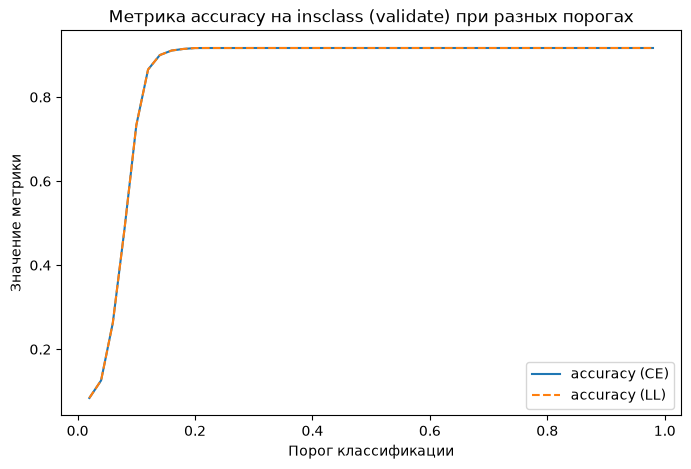

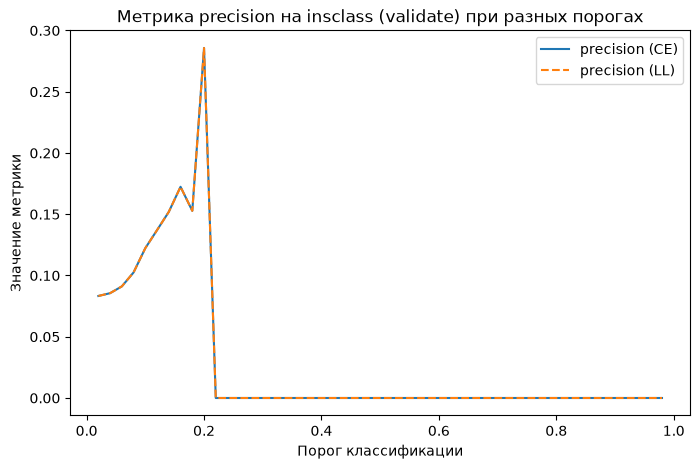

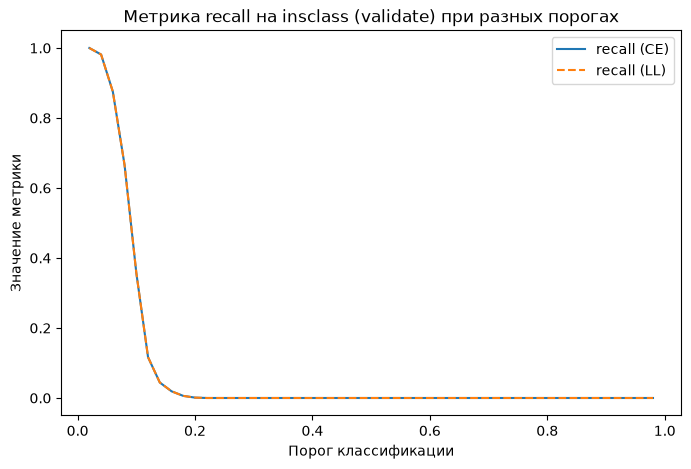

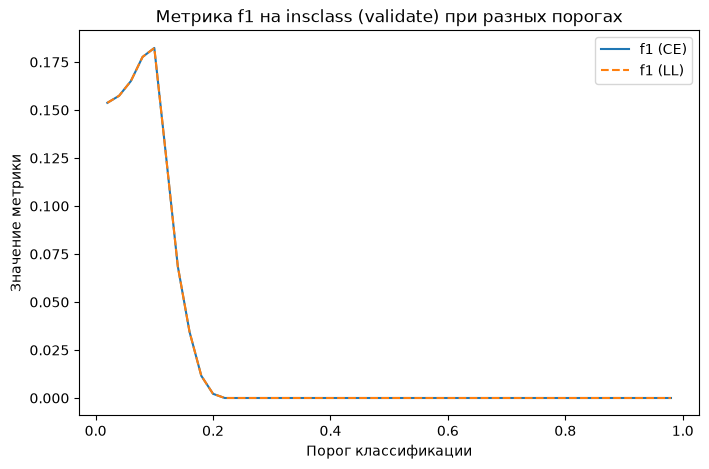

Метрики при пороге 0.50   : accuracy=0.917, precision=0.000, recall=0.000, f1=0.000
Лучший порог по F1: 0.10 (F1=0.182)
Метрики при лучшем пороге : accuracy=0.733, precision=0.122, recall=0.358, f1=0.182


In [9]:
# Зависимость метрик от порога классификации (валидационная выборка insclass)
thresholds = np.linspace(0.02, 0.98, 49)
models = [("CE", m_ce), ("LL", m_ll)]
curves = {}
for tag, m in models:
    proba = np.asarray(m.predict(Xva)).ravel()
    curves[tag] = {
        "accuracy": [float(((proba > thr) == yva).mean()) for thr in thresholds],
        "precision": [float(m.precision(Xva, yva, threshold=thr)) for thr in thresholds],
        "recall": [float(m.recall(Xva, yva, threshold=thr)) for thr in thresholds],
        "f1": [float(m.f1(Xva, yva, threshold=thr)) for thr in thresholds],
    }
for name in ["accuracy", "precision", "recall", "f1"]:
    plt.figure(figsize=(8, 5))
    for tag, _ in models:
        plt.plot(thresholds, curves[tag][name], "-" if tag == "CE" else "--",
                 label=f"{name} ({tag})")
    plt.title(f"Метрика {name} на insclass (validate) при разных порогах")
    plt.xlabel("Порог классификации")
    plt.ylabel("Значение метрики")
    plt.legend()
    plt.show()
i05 = int(np.argmin(np.abs(thresholds - 0.5)))
i_best = int(np.argmax(curves["CE"]["f1"]))
print("Метрики при пороге 0.50   :", ", ".join(f"{n}={curves['CE'][n][i05]:.3f}" for n in curves["CE"]))
print(f"Лучший порог по F1: {thresholds[i_best]:.2f} (F1={curves['CE']['f1'][i_best]:.3f})")
print("Метрики при лучшем пороге :", ", ".join(f"{n}={curves['CE'][n][i_best]:.3f}" for n in curves["CE"]))

## Матрица путаницы на insclass

Матрицей путаницы (confusion matrix) называют таблицу, в строках которой указаны фактические классы, а в столбцах — предсказанные; на диагонали стоят правильные ответы, а вне её — ошибки двух видов: ложные срабатывания (FP) и ложные пропуски (FN).

На рисунке ниже сравниваются матрицы путаницы CE и LL на валидационной выборке при пороге 0.5. Из-за дисбаланса классов обе модели относят все договоры к классу «без риска»: правая колонка (предсказанные рисковые) пуста, а все истинно рисковые договоры становятся ложноотрицательными, поэтому recall положительного класса равен нулю.

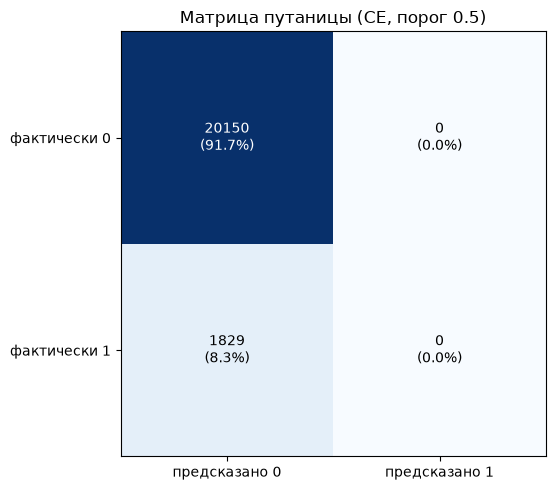

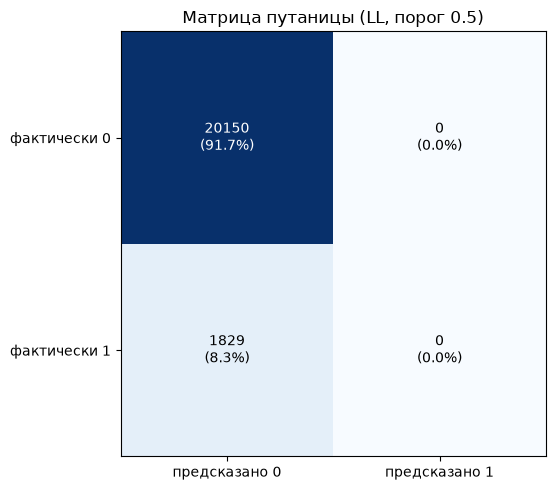

In [10]:
# Матрицы путаницы CE и LL (validate, порог 0.5)
for tag, m in models:
    tn, fp, fn, tp = m.confusion_matrix(Xva, yva)
    cm = np.array([[tn, fp], [fn, tp]])
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        color = "white" if v > cm.max() / 2 else "black"
        plt.text(j, i, f"{v}\n({v / cm.sum() * 100:.1f}%)", ha="center", va="center", color=color)
    plt.title(f"Матрица путаницы ({tag}, порог 0.5)")
    plt.xticks([0, 1], ["предсказано 0", "предсказано 1"])
    plt.yticks([0, 1], ["фактически 0", "фактически 1"])
    plt.tight_layout()
    plt.show()

## Проверка ценности строковых признаков

ROC-кривой называют график зависимости доли истинноположительных ответов от доли ложноположительных при переборе порога классификации; AUC - это площадь под этой кривой, характеризующая способность модели ранжировать объекты независимо от порога.

Наш градиентный спуск с 10000 шагов на дисбалансированных данных недообучается, поэтому для проверки того, что закодированные строковые признаки несут информацию, обе модели обучаются полносвязной логистической регрессией sklearn на тех же разбиениях и признаках: только 10 числовых признаков и те же плюс 6 закодированных строковых. Сравнивается ROC AUC на валидационной выборке.

числовые признаки: validate AUC = 0.5978
+ закодированные строковые: validate AUC = 0.6094


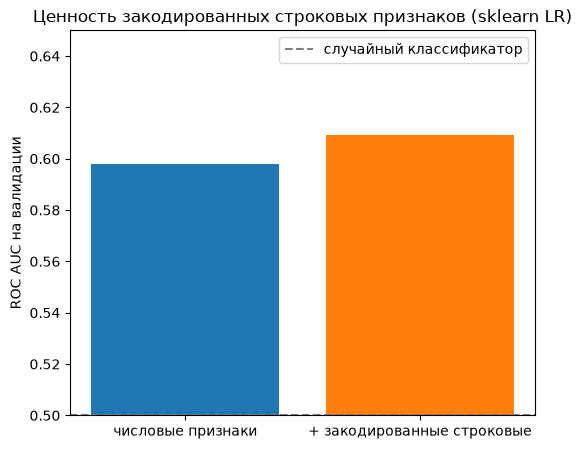

In [11]:
# Сравнение AUC: только числовые признаки vs + закодированные строковые
# (тот же функционал и разбиение, но сошедшаяся оптимизация sklearn)
from sklearn.linear_model import LogisticRegression as SkLogReg
from sklearn.metrics import roc_auc_score

Xtr_n, _ = scaled_matrix(train_s, scaler, add_intercept=False)
Xva_n, _ = scaled_matrix(validate_s, scaler, add_intercept=False)
variants = [
    ("числовые признаки", Xtr_n, Xva_n),
    ("+ закодированные строковые",
     np.hstack([Xtr_n, encode_string_features(train_s, train_s)]),
     np.hstack([Xva_n, encode_string_features(train_s, validate_s)])),
]
aucs = []
for tag, Xa, Xb in variants:
    m = SkLogReg(max_iter=2000).fit(Xa, ytr)
    auc = roc_auc_score(yva, m.predict_proba(Xb)[:, 1])
    aucs.append(auc)
    print(f"{tag}: validate AUC = {auc:.4f}")
plt.figure(figsize=(6, 5))
plt.bar([v[0] for v in variants], aucs, color=["#1f77b4", "#ff7f0e"])
plt.axhline(0.5, linestyle="--", color="gray", label="случайный классификатор")
plt.ylim(0.5, 0.65)
plt.ylabel("ROC AUC на валидации")
plt.title("Ценность закодированных строковых признаков (sklearn LR)")
plt.legend()
plt.show()

## Итоговые результаты

Метрики CE и LL совпадают, так как оба способа обучения реализуют одну и ту же оптимизацию (LL = −CE). Метрики приведены на валидационной выборке insclass (21979 договоров, положительный класс — «рисковый», ~8%).

| Метрика | Порог 0.5 | Лучший порог (0.10) |
|---|---|---|
| Accuracy | 0.9168 | 0.733 |
| Precision | 0.0000 | 0.122 |
| Recall | 0.0000 | 0.358 |
| F1-мера | 0.0000 | 0.182 |
| Confusion matrix | TN=20150, FP=0, FN=1829, TP=0 | — |